In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [28]:
df = pd.read_csv('Student_Performance.csv')

In [29]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


| اسم العمود                       | الشرح بالعربي                                               | نوع البيانات   | مثال       |
| -------------------------------- | ----------------------------------------------------------- | -------------- | ---------- |
| Hours Studied                    | عدد الساعات التي قضاها الطالب في المذاكرة                   | رقمية          | 7 ساعات    |
| Previous Scores                  | درجات الطالب في الاختبارات السابقة                          | رقمية          | 99 درجة    |
| Extracurricular Activities       | هل يشارك الطالب في أنشطة خارج الدراسة أم لا                 | فئوية          | Yes / No   |
| Sleep Hours                      | عدد ساعات نوم الطالب يوميًا                                 | رقمية          | 9 ساعات    |
| Sample Question Papers Practiced | عدد نماذج الأسئلة التي تدرب الطالب على حلها                 | رقمية          | نموذج واحد |
| Performance Index                | مؤشر الأداء الدراسي للطالب، وهو القيمة التي نريد التنبؤ بها | رقمية (Target) | 91         |


In [30]:
df.isnull().sum().sort_values(ascending=False)

Sample Question Papers Practiced    2856
Extracurricular Activities          1572
Previous Scores                        0
Hours Studied                          0
Sleep Hours                            0
Performance Index                      0
dtype: int64

In [31]:
df.shape

(10000, 6)

In [32]:
df['Sample Question Papers Practiced'].describe()

count    7144.000000
mean        4.572788
std         2.868633
min         0.000000
25%         2.000000
50%         5.000000
75%         7.000000
max         9.000000
Name: Sample Question Papers Practiced, dtype: float64

<Axes: ylabel='Sample Question Papers Practiced'>

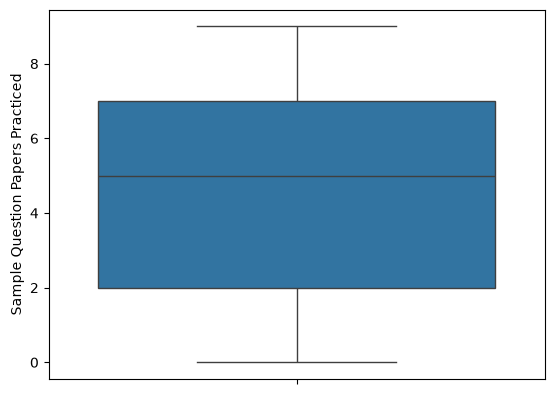

In [33]:
sns.boxplot(df['Sample Question Papers Practiced'])

In [34]:
df['Sample Question Papers Practiced'].skew()

np.float64(-0.04025761626052511)

<Axes: xlabel='Sample Question Papers Practiced', ylabel='Count'>

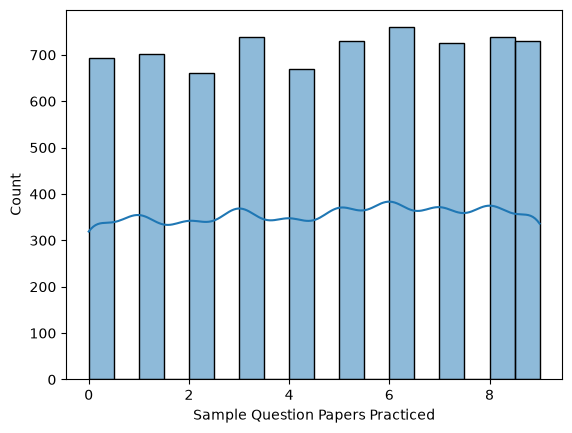

In [35]:
sns.histplot(df['Sample Question Papers Practiced'],kde=True)

In [36]:
df['Sample Question Papers Practiced']=df['Sample Question Papers Practiced'].fillna(df['Sample Question Papers Practiced'].median())

In [37]:

df['Extracurricular Activities'].value_counts()

Extracurricular Activities
No     4251
Yes    4177
Name: count, dtype: int64

In [38]:
df['Extracurricular Activities']=df['Extracurricular Activities'].fillna(df['Extracurricular Activities'].mode()[0])

In [39]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [40]:
df.isnull().sum().sort_values()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [41]:
df.duplicated().sum()

np.int64(192)

In [42]:
df.drop_duplicates(inplace=True)

In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
df.info()

<class 'pandas.DataFrame'>
Index: 9808 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     9808 non-null   int64  
 1   Previous Scores                   9808 non-null   int64  
 2   Extracurricular Activities        9808 non-null   str    
 3   Sleep Hours                       9808 non-null   int64  
 4   Sample Question Papers Practiced  9808 non-null   float64
 5   Performance Index                 9808 non-null   int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 536.4 KB


In [45]:
df['Sample Question Papers Practiced'].unique()

array([1., 2., 5., 6., 4., 3., 0., 7., 8., 9.])

In [46]:
df['Sample Question Papers Practiced']=df['Sample Question Papers Practiced'].astype(int)

In [47]:
df.info()

<class 'pandas.DataFrame'>
Index: 9808 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype
---  ------                            --------------  -----
 0   Hours Studied                     9808 non-null   int64
 1   Previous Scores                   9808 non-null   int64
 2   Extracurricular Activities        9808 non-null   str  
 3   Sleep Hours                       9808 non-null   int64
 4   Sample Question Papers Practiced  9808 non-null   int64
 5   Performance Index                 9808 non-null   int64
dtypes: int64(5), str(1)
memory usage: 536.4 KB


In [48]:
df['Extracurricular Activities'] = df['Extracurricular Activities'].map({'Yes': 1,'No': 0})

In [49]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91
1,4,82,0,4,2,65
2,8,51,1,7,2,45
3,5,52,1,5,2,36
4,7,75,0,8,5,66


In [50]:
df.describe()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,9808.000000,9808.000000,9808.000000,9808.000000,9808.000000,9808.000000
mean,4.991232,69.421697,0.417720,6.530587,4.693312,55.193414
std,2.590648,17.343635,0.493209,1.697977,2.442684,19.225638
min,1.000000,40.000000,0.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,0.000000,5.000000,3.000000,40.000000
50%,5.000000,69.000000,0.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,1.000000,8.000000,6.000000,71.000000
max,9.000000,99.000000,1.000000,9.000000,9.000000,100.000000


In [51]:
X = df.drop(columns=['Performance Index'])
y = df['Performance Index']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [52]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [53]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

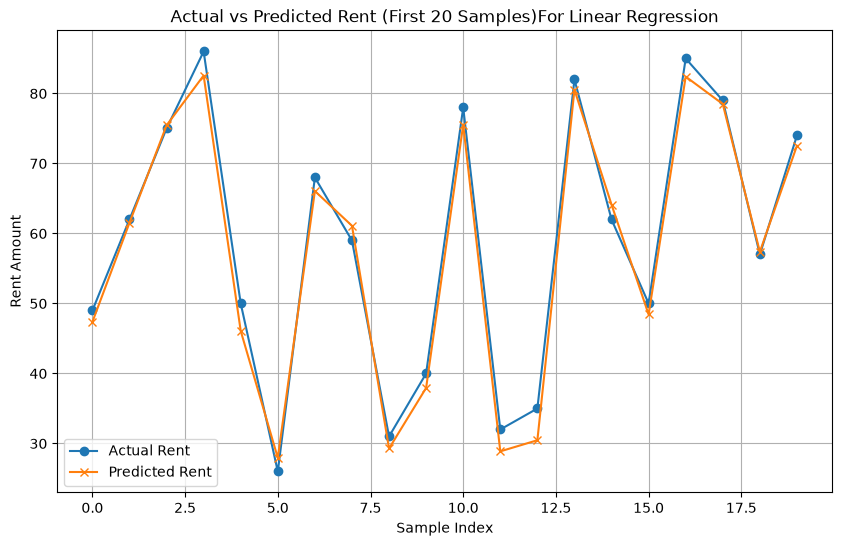

  7%|▋         | 1/15 [00:00<00:02,  6.28it/s]

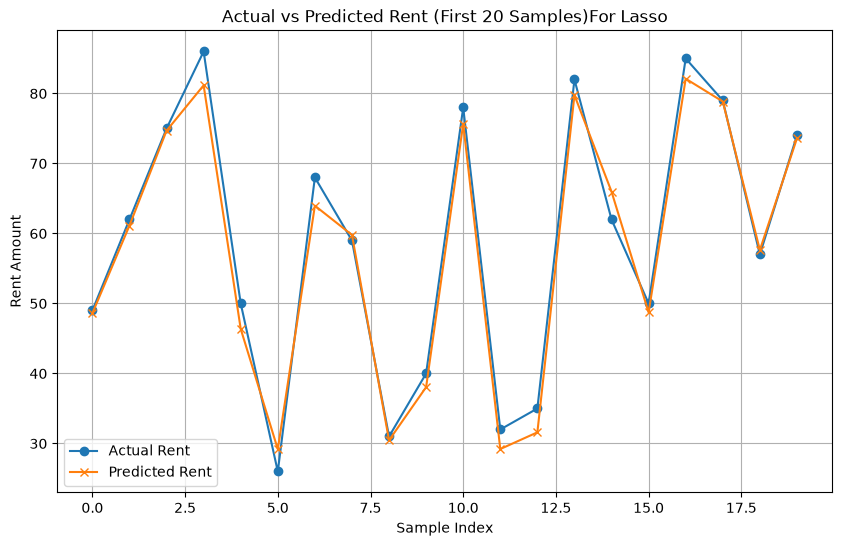

 13%|█▎        | 2/15 [00:00<00:01,  7.37it/s]

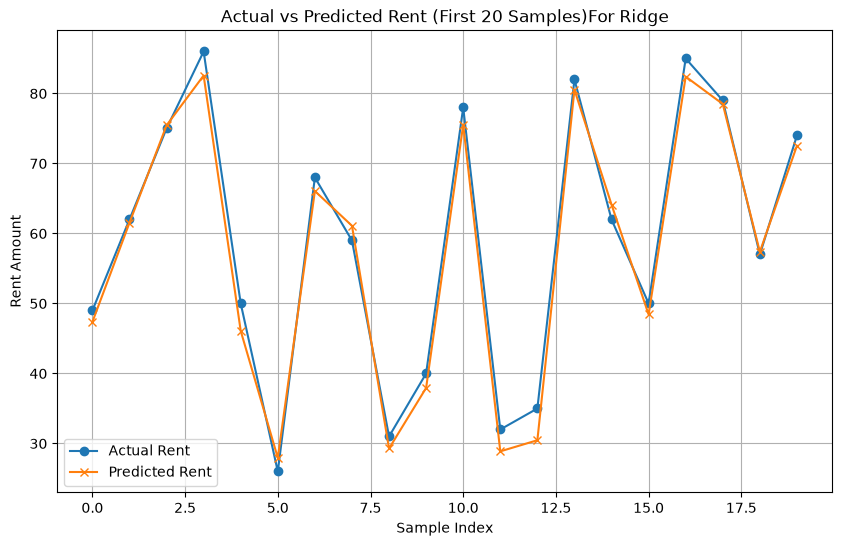

 20%|██        | 3/15 [00:00<00:01,  7.98it/s]

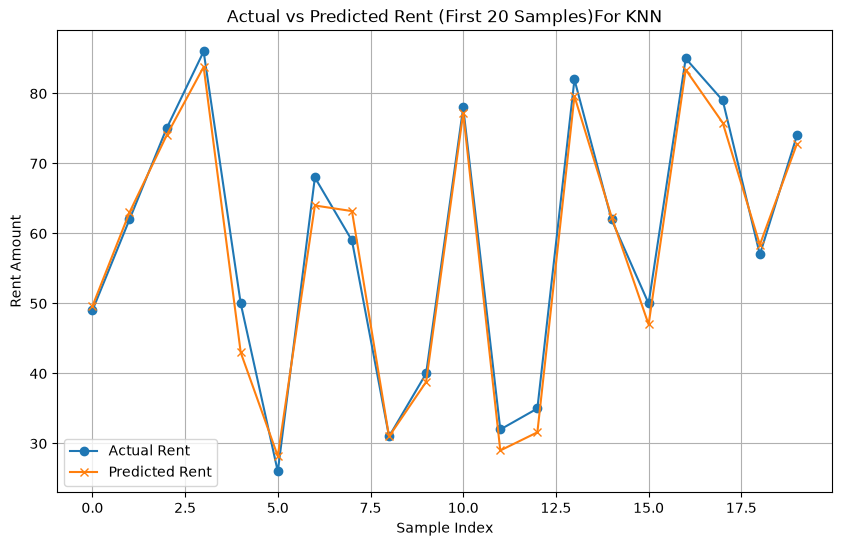

 27%|██▋       | 4/15 [00:00<00:01,  7.08it/s]

In [ ]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [ ]:
results_df = pd.DataFrame(errors).T
display(results_df)

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Linear Regression,1.643715,1.672503,4.273845,4.455024,2.067328,2.110693,0.988388,0.988143
Lasso,1.780888,1.799890,4.984601,5.233878,2.232622,2.287767,0.986457,0.986070
Ridge,1.643717,1.672508,4.273845,4.455060,2.067328,2.110701,0.988388,0.988142
KNN,1.662988,2.033129,4.333841,6.569358,2.081788,2.563076,0.988225,0.982515
SVM,1.643530,1.671969,4.275086,4.451305,2.067628,2.109812,0.988385,0.988152
Decision Tree,1.405616,2.082744,3.233249,6.845532,1.798124,2.616397,0.991215,0.981780
Random Forest,1.328895,1.840744,2.746592,5.406523,1.657284,2.325193,0.992537,0.985610
ExtraTrees,0.211788,2.173383,0.389568,7.346107,0.624154,2.710370,0.998942,0.980448
Bagging,1.327447,1.845385,2.750361,5.394479,1.658421,2.322602,0.992527,0.985642
AdaBoost,2.856082,2.903025,12.716237,13.542871,3.565983,3.680064,0.965450,0.963955
